In [2]:
import os
os.environ["HF_HOME"] = "/root/face-verification/hf_cache"

import gc
import json
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm.auto import tqdm
from transformers import ResNetModel
from datasets import load_dataset

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [3]:
ds = load_dataset("SaffalPoosh/casia_web_face")

Resolving data files:   0%|          | 0/20 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/20 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/20 [00:00<?, ?it/s]

In [4]:
test_ratio = 0.1 # use 10% of labels as test data

data = ds["train"]

lbl_to_idx: dict = {} # labels to images indices mapping
for i, lbl in enumerate(data["label"]):
    if lbl not in lbl_to_idx:
        lbl_to_idx[lbl] = []
    lbl_to_idx[lbl].append(i)

rnd_lbls = list(lbl_to_idx) # flatten
random.Random(42).shuffle(rnd_lbls)

test_count = round(len(rnd_lbls) * test_ratio)
lbls_test = rnd_lbls[:test_count]
lbls_train = rnd_lbls[test_count:]

lbl_to_idx_test = { lbl: lbl_to_idx[lbl] for lbl in lbls_test }
lbl_to_idx_train = { lbl: lbl_to_idx[lbl] for lbl in lbls_train }

In [5]:
tf_resize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

tf_native = transforms.Compose([
    transforms.ToTensor()
])

tf_normalize = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [6]:
class PairDataset(Dataset):
    def __init__(self, by_label, length, seed=0, tf=tf_resize):
        self.by_label, self.length, self.seed, self.tf = by_label, length, seed, tf
        self.labels = list(by_label)
        self.multi = [l for l in self.labels if len(by_label[l]) >= 2]

    def __len__(self):
        return self.length

    def __getitem__(self, k):
        rng = random.Random(self.seed * 10_000_000 + k)
        if k % 2 == 0:
            i, j = rng.sample(self.by_label[rng.choice(self.multi)], 2)
            t = 1.0
        else:
            la, lb = rng.sample(self.labels, 2)
            i, j = rng.choice(self.by_label[la]), rng.choice(self.by_label[lb])
            t = -1.0
        a = self.tf(data[i]["image"].convert("RGB"))
        b = self.tf(data[j]["image"].convert("RGB"))
        return a, b, torch.tensor(t)


class PositivePairDataset(Dataset):
    def __init__(self, lbl_to_idx, length, seed=0, tf=tf_resize):
        self.lbl_to_idx = lbl_to_idx
        self.length = length
        self.seed = seed
        self.tf = tf
        self.multi = [lbl for lbl in lbl_to_idx if len(lbl_to_idx[lbl]) >= 2]

    def __len__(self):
        return self.length

    def __getitem__(self, k):
        rng = random.Random(self.seed * 10_000_000 + k)
        lbl = rng.choice(self.multi)
        i, j = rng.sample(self.lbl_to_idx[lbl], 2)
        a = self.tf(data[i]["image"].convert("RGB"))
        b = self.tf(data[j]["image"].convert("RGB"))
        return a, b, lbl


test_resize = PairDataset(lbl_to_idx_test, 2000, seed=0, tf=tf_resize)
test_native = PairDataset(lbl_to_idx_test, 2000, seed=0, tf=tf_native)
test_normalize = PairDataset(lbl_to_idx_test, 1000, seed=0, tf=tf_normalize)

In [7]:
class ResnetEncoderWithHeadModel(nn.Module):
    def __init__(self, backbone, head=None):
        super().__init__()
        self.backbone = backbone
        self.head = head if head is not None else nn.Identity()

    def forward(self, x):
        return F.normalize(self.head(self.backbone(x).pooler_output.flatten(1)), dim=1)


def make_model(head=None, channels_last=False):
    resnet = ResNetModel.from_pretrained("microsoft/resnet-50")
    model = ResnetEncoderWithHeadModel(resnet, head)
    if channels_last:
        return model.to(device, memory_format=torch.channels_last)
    return model.to(device)


def evaluate(encoder, dataset, batch_size=128, num_workers=4):
    encoder.eval()
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers)

    similarities = []
    labels = []
    with torch.no_grad():
        for a, b, t in loader:
            za = encoder(a.to(device))
            zb = encoder(b.to(device))
            similarities.extend((za * zb).sum(dim=1).cpu().tolist())
            labels.extend((t == 1).int().tolist())

    similarities = np.array(similarities)
    labels = np.array(labels)

    false_positive_rate, true_positive_rate, thresholds = roc_curve(labels, similarities)
    true_negative_rate = 1 - false_positive_rate
    area_under_curve = roc_auc_score(labels, similarities)
    accuracy = ((true_positive_rate + true_negative_rate) / 2).max()
    return area_under_curve, accuracy, similarities, labels


def pair_loss(sims, y, margin):
    losses = []
    for sim, is_same in zip(sims, y):
        if is_same == 1:
            losses.append(1 - sim)
        else:
            losses.append(max(0, sim - margin))
    return sum(losses) / len(losses)


def hard_negative_loss(za, zb, labels, margin, k=1):
    sims = za @ zb.T
    positives = sims.diag()
    same_person = labels[:, None] == labels[None, :]
    negatives = sims.masked_fill(same_person, -1.0)

    hardest_for_a = negatives.topk(k, dim=1).values
    hardest_for_b = negatives.topk(k, dim=0).values

    pos_loss = 1 - positives
    neg_loss = (F.relu(hardest_for_a - margin).mean(dim=1)
                + F.relu(hardest_for_b - margin).mean(dim=0)) / 2
    return (pos_loss + neg_loss).mean()

In [11]:
import time


def train(encoder, run_name: str, epochs: int, margin: float, test_dataset, tf=tf_resize,
          lr: float = 1e-4, head_lr: float = None, batch_size: int = 64, pairs_per_epoch: int = 50_000,
          num_workers: int = 4, seed: int = 0, bf16: bool = False, channels_last: bool = False,
          hard_negatives: bool = False, k: int = 1, epoch_offset: int = 0):
    torch.manual_seed(seed)
    if head_lr is None:
        opt = torch.optim.AdamW(encoder.parameters(), lr=lr)
    else:
        opt = torch.optim.AdamW([
          {"params": encoder.backbone.parameters(), "lr": lr},
          {"params": encoder.head.parameters(), "lr": head_lr},
        ])
    loss_fn = nn.CosineEmbeddingLoss(margin=margin)
    memory_format = torch.channels_last if channels_last else torch.contiguous_format
    history = []

    for epoch in tqdm(range(epochs), desc=run_name):
        epoch_count = epoch + epoch_offset
        if hard_negatives:
            dataset = PositivePairDataset(lbl_to_idx_train, pairs_per_epoch, seed=seed * 1000 + epoch_count, tf=tf)
        else:
            dataset = PairDataset(lbl_to_idx_train, pairs_per_epoch, seed=seed * 1000 + epoch_count, tf=tf)
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)

        train_start = time.perf_counter()
        encoder.train()
        batch_losses = []
        for a, b, t in tqdm(loader, desc=f"epoch {epoch_count}", leave=False):
            a, b, t = a.to(device, memory_format=memory_format), b.to(device, memory_format=memory_format), t.to(device)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=bf16):
                za = encoder(a)
                zb = encoder(b)
            if hard_negatives:
                loss = hard_negative_loss(za.float(), zb.float(), t, margin, k)
            else:
                loss = loss_fn(za.float(), zb.float(), t)
            opt.zero_grad()
            loss.backward()
            opt.step()
            batch_losses.append(loss.item())
        del loader
        gc.collect()
        train_time = time.perf_counter() - train_start

        eval_start = time.perf_counter()
        auc, acc, sims, y = evaluate(encoder, test_dataset)
        eval_time = time.perf_counter() - eval_start

        history.append({
            "epoch": epoch_count,
            "train_loss": float(np.mean(batch_losses)),
            "val_loss": float(pair_loss(sims, y, margin)),
            "val_auc": float(auc),
            "val_acc": float(acc),
            "train_time": train_time,
            "eval_time": eval_time,
            "batch_losses": batch_losses,
        })
        print({key: v for key, v in history[-1].items() if key != "batch_losses"})

        with open(f"history_cache/history_{run_name}.json", "w") as f:
            json.dump(history, f)
        torch.save(encoder.state_dict(), f"pt_cache/{run_name}_epoch{epoch_count}.pt")

    return history

In [9]:
def visualize_history(run_name: str):
    with open(f"history_cache/history_{run_name}.json") as f:
        history = json.load(f)

    epochs = [h["epoch"] for h in history]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, [h["val_auc"] for h in history], "o-")
    ax1.set(xlabel="epoch", ylabel="AUC", title="Validation AUC")

    ax2.plot(epochs, [h["train_loss"] for h in history], "o-", label="train")
    ax2.plot(epochs, [h["val_loss"] for h in history], "o-", label="validation")
    ax2.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax2.legend()

    plt.tight_layout()
    plt.show()

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_encoder:   0%|          | 0/5 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.3147872280319938, 'val_loss': 0.2671200266867855, 'val_auc': 0.7526509999999998, 'val_acc': 0.6855, 'train_time': 514.899742051959, 'eval_time': 7.90598295070231}


...

{'epoch': 2, 'train_loss': 0.2018999674493242, 'val_loss': 0.19180878503732202, 'val_auc': 0.8160470000000001, 'val_acc': 0.754, 'train_time': 515.8333145976067, 'eval_time': 7.945037035271525}


epoch 3:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.1942415909027047, 'val_loss': 0.17924789719395176, 'val_auc': 0.8400200000000001, 'val_acc': 0.7685, 'train_time': 515.87380621396, 'eval_time': 7.94751033000648}


epoch 4:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 4, 'train_loss': 0.18354968823816464, 'val_loss': 0.1754056289367362, 'val_auc': 0.8507730000000001, 'val_acc': 0.778, 'train_time': 515.6079966910183, 'eval_time': 7.943735862150788}


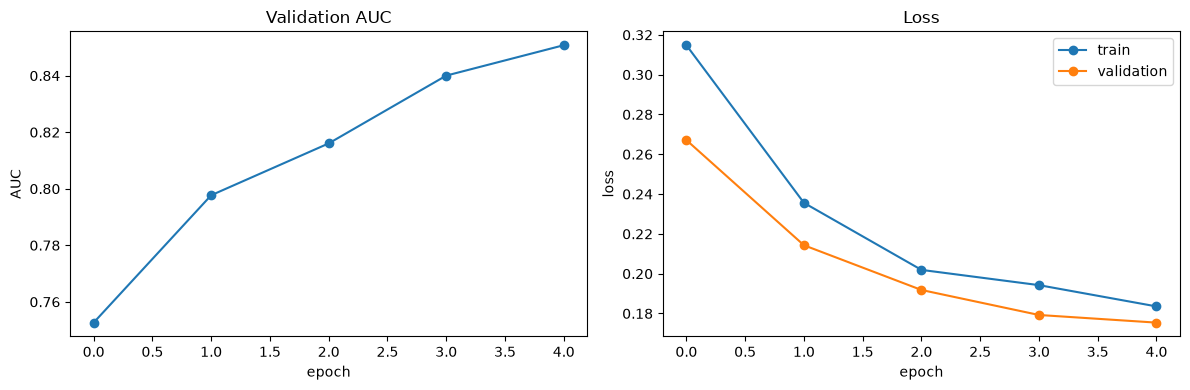

In [10]:
# now we train the plain resnet encoder
run_name = "resnet_encoder"
model = make_model()
history = train(model, run_name=run_name, epochs=5, margin=0.3, test_dataset=test_resize)
visualize_history(run_name)

In [11]:
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_capability(0))

NVIDIA RTX 4000 SFF Ada Generation
(8, 9)


Alright, that was slow (96 minutes). We will try to make it faster. First we try using bf16 for the training process instead of f32

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_encoder_with_bf16:   0%|          | 0/5 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.31544340773464163, 'val_loss': 0.26900460831895295, 'val_auc': 0.747028, 'val_acc': 0.6795, 'train_time': 303.8598351441324, 'eval_time': 7.941020216792822}


...

{'epoch': 2, 'train_loss': 0.20067256955844362, 'val_loss': 0.19202781334221183, 'val_auc': 0.8110870000000001, 'val_acc': 0.751, 'train_time': 303.38722792081535, 'eval_time': 7.911100400611758}


epoch 3:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.1934289430051356, 'val_loss': 0.18591807046532466, 'val_auc': 0.8217625, 'val_acc': 0.756, 'train_time': 303.1006768364459, 'eval_time': 7.920365398749709}


epoch 4:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 4, 'train_loss': 0.18457979897556404, 'val_loss': 0.1804642563562824, 'val_auc': 0.8271565, 'val_acc': 0.766, 'train_time': 303.5090414509177, 'eval_time': 7.934326445683837}


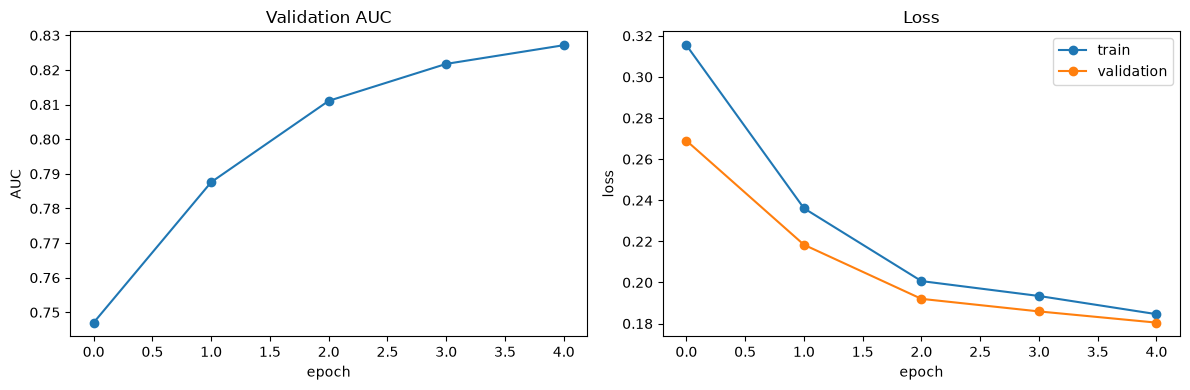

In [12]:
run_name = "resnet_encoder_with_bf16"
model = make_model()
history = train(model, run_name=run_name, epochs=5, margin=0.3, test_dataset=test_resize, bf16=True)
visualize_history(run_name)

So about 60 minutes in total, so around 60% faster. So now we can perform an experiment in about an hour.
Another speed improvement we will attempt is to use a different memory format, the channels_last format.

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_encoder_with_bf16_channels_last:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.31478980587571476, 'val_loss': 0.2680303133785704, 'val_auc': 0.746992, 'val_acc': 0.6805, 'train_time': 263.375230031088, 'eval_time': 7.813555965200067}


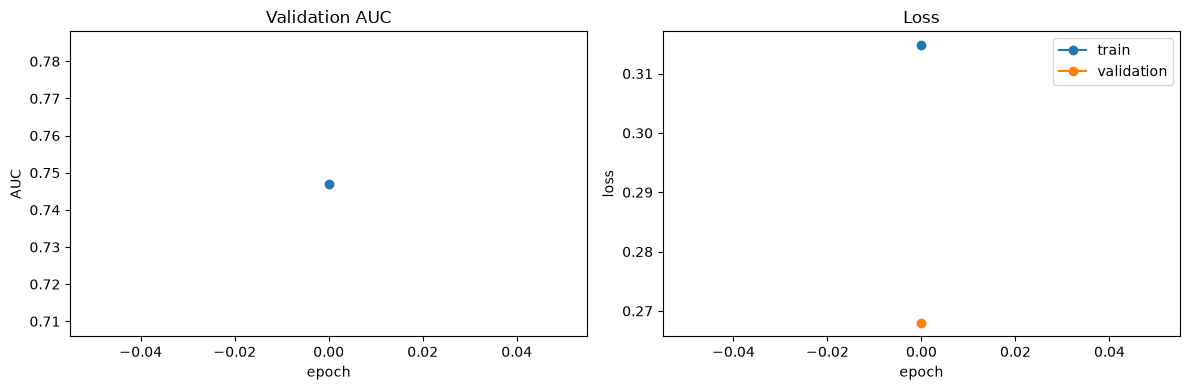

In [13]:
run_name = "resnet_encoder_with_bf16_channels_last"
model = make_model(channels_last=True)
# we only do 1 epoch since we initially just want to measure speed
history = train(model, run_name=run_name, epochs=1, margin=0.3, test_dataset=test_resize, bf16=True, channels_last=True)
visualize_history(run_name)

That took about 5 minutes less, so about 10% faster. 

# Below we start experimenting with an additional head

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_encoder_with_head:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.2816772289059656, 'val_loss': 0.23620576608031726, 'val_auc': 0.760428, 'val_acc': 0.6970000000000001, 'train_time': 262.80577874928713, 'eval_time': 7.79075988009572}


...

{'epoch': 7, 'train_loss': 0.1627083469344222, 'val_loss': 0.1562271262148381, 'val_auc': 0.8867370000000001, 'val_acc': 0.8195, 'train_time': 262.67541970312595, 'eval_time': 7.7880393005907536}


epoch 8:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.15872464567194206, 'val_loss': 0.15624763149265075, 'val_auc': 0.8833489999999999, 'val_acc': 0.8140000000000001, 'train_time': 262.50476215966046, 'eval_time': 7.823313063010573}


epoch 9:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.1584189811535656, 'val_loss': 0.15209176391698295, 'val_auc': 0.8898714999999999, 'val_acc': 0.8260000000000001, 'train_time': 264.62468324787915, 'eval_time': 7.791396154090762}


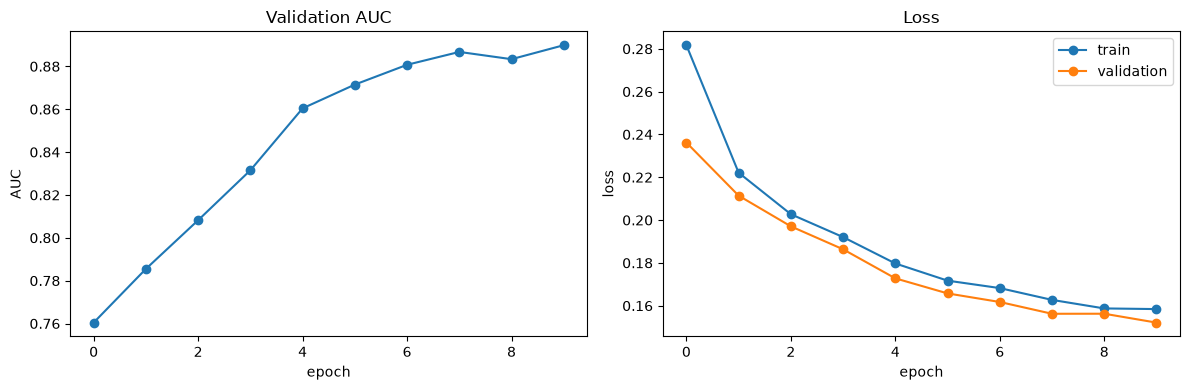

In [14]:
# now we train the resnet encoder with a head
run_name = "resnet_encoder_with_head"
model = make_model(head=nn.Linear(2048, 512), channels_last=True)
history = train(model, run_name=run_name, epochs=10, margin=0.3, test_dataset=test_resize, bf16=True, channels_last=True)
visualize_history(run_name)

A problem is that we are training an untrained head, and a pretrained encoder. Intuitively the untrained head should have a higher learning rate. We try this

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_encoder_with_head_lr:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.26396441069024296, 'val_loss': 0.2229818040788149, 'val_auc': 0.771492, 'val_acc': 0.7195, 'train_time': 263.5663087349385, 'eval_time': 7.841953806579113}


...

{'epoch': 7, 'train_loss': 0.1616797589832712, 'val_loss': 0.1605534810908125, 'val_auc': 0.881516, 'val_acc': 0.819, 'train_time': 262.549666011706, 'eval_time': 7.834827641025186}


epoch 8:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.15902078350829651, 'val_loss': 0.1591122214552002, 'val_auc': 0.881743, 'val_acc': 0.8215, 'train_time': 262.672898568213, 'eval_time': 7.799572627991438}


epoch 9:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.1581379650517955, 'val_loss': 0.15672941707409785, 'val_auc': 0.888691, 'val_acc': 0.8160000000000001, 'train_time': 263.2972773164511, 'eval_time': 7.832222307100892}


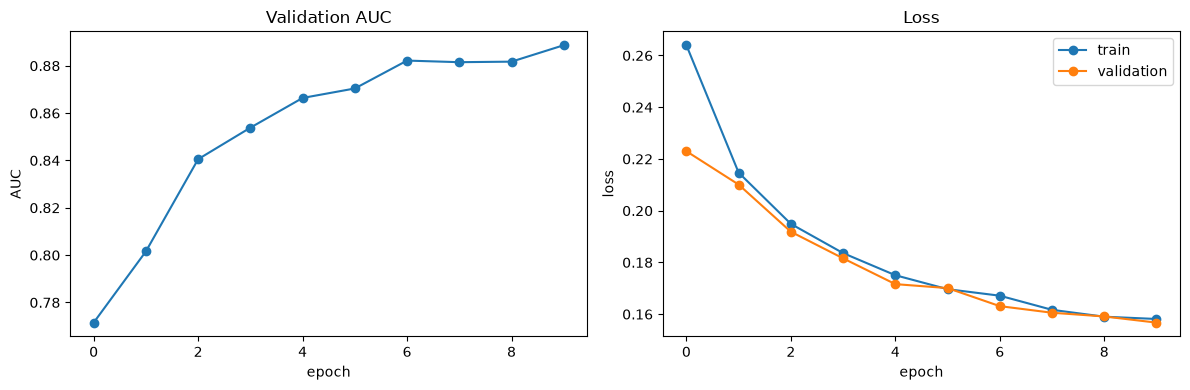

In [15]:
run_name = "resnet_encoder_with_head_lr"
model = make_model(head=nn.Linear(2048, 512), channels_last=True)
history = train(model, run_name=run_name, epochs=10, margin=0.3, test_dataset=test_resize, head_lr=1e-3, bf16=True, channels_last=True)
visualize_history(run_name)

Did not make huge improvements
Normally resnet uses 224 x 224 images, and ours are not, so we resize. But resnet actually accepts any size, so we now try with a different transform.

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_head_no_resize:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.2689453394669096, 'val_loss': 0.23832977150752863, 'val_auc': 0.758953, 'val_acc': 0.696, 'train_time': 80.09719681181014, 'eval_time': 2.1236228439956903}


...

{'epoch': 7, 'train_loss': 0.17116718219064386, 'val_loss': 0.16646680946741102, 'val_auc': 0.8755729999999999, 'val_acc': 0.804, 'train_time': 79.61607575044036, 'eval_time': 2.081796793267131}


epoch 8:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.16554699561861166, 'val_loss': 0.16483691754117472, 'val_auc': 0.8745265, 'val_acc': 0.804, 'train_time': 79.66033346578479, 'eval_time': 2.0885914154350758}


epoch 9:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.16522736301469376, 'val_loss': 0.16199345824792838, 'val_auc': 0.8779440000000001, 'val_acc': 0.8109999999999999, 'train_time': 79.55560210347176, 'eval_time': 2.0866090953350067}


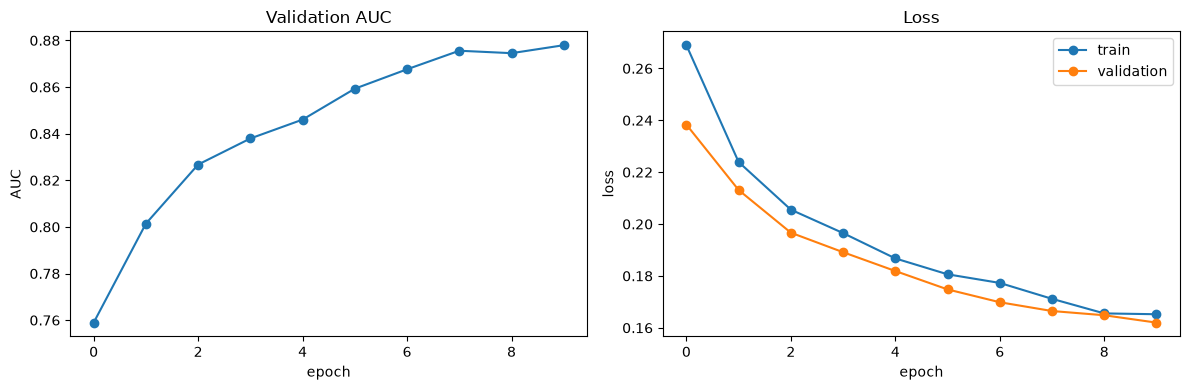

In [16]:
run_name = "resnet_head_no_resize"
model = make_model(head=nn.Linear(2048, 512), channels_last=True)
history = train(model, run_name=run_name, epochs=10, margin=0.3, test_dataset=test_native, tf=tf_native, head_lr=1e-3, bf16=True, channels_last=True)
visualize_history(run_name)

This made training a lot faster as expected, but it also improved accuracy and auc a bit, which was not expected. 
We can now finetune such a model in 13 minutes. About 7,4 times faster than the first finetuning, even though this model has additional parameters in the head.

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_head_no_resize_20e:   0%|          | 0/20 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.19521053625113519, 'val_loss': 0.17322931664437055, 'val_auc': 0.744859, 'val_acc': 0.6915, 'train_time': 79.51675477810204, 'eval_time': 2.0633168257772923}


...

{'epoch': 17, 'train_loss': 0.10677614943850833, 'val_loss': 0.10488106863945723, 'val_auc': 0.8956480000000001, 'val_acc': 0.8275, 'train_time': 79.8000563159585, 'eval_time': 2.0807214993983507}


epoch 18:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 18, 'train_loss': 0.10447122209974567, 'val_loss': 0.10430431219935417, 'val_auc': 0.896232, 'val_acc': 0.8320000000000001, 'train_time': 79.81366822682321, 'eval_time': 2.1018149442970753}


epoch 19:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 19, 'train_loss': 0.1048703545137592, 'val_loss': 0.10417213125526906, 'val_auc': 0.8984319999999999, 'val_acc': 0.833, 'train_time': 79.63944462500513, 'eval_time': 2.094469152390957}


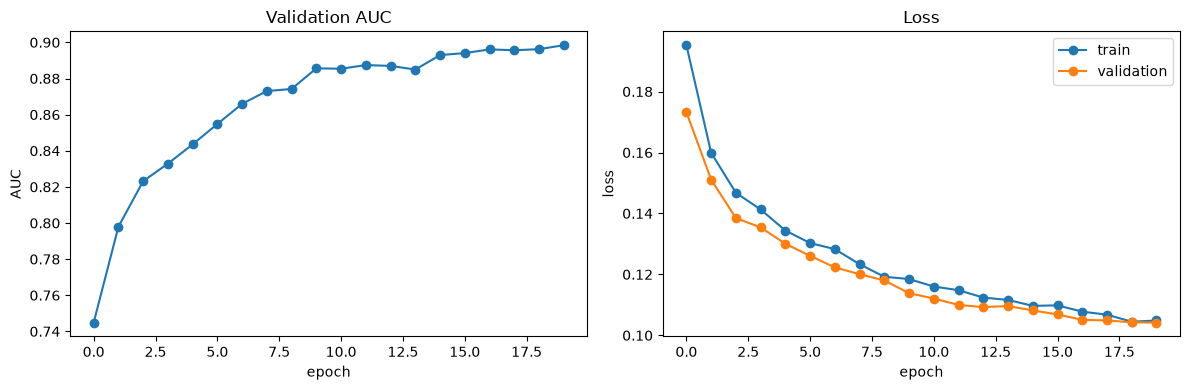

In [17]:
run_name = "resnet_head_no_resize_20e"
model = make_model(head=nn.Linear(2048, 512), channels_last=True)
history = train(model, run_name=run_name, epochs=20, margin=0.5, test_dataset=test_native, tf=tf_native,
                head_lr=1e-3, bf16=True, channels_last=True)
visualize_history(run_name)

So it looks to overfit after 10 epochs. What cause the jump in LR after 10 epochs though?

We would still like a better AUC and ACC though. Let's try 

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_w_normalize:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.19382747316070834, 'val_loss': 0.1661613772511482, 'val_auc': 0.769036, 'val_acc': 0.712, 'train_time': 79.65394706092775, 'eval_time': 1.2302324678748846}


...

{'epoch': 7, 'train_loss': 0.12203172267512287, 'val_loss': 0.11808487702906131, 'val_auc': 0.87866, 'val_acc': 0.8069999999999999, 'train_time': 79.97028644010425, 'eval_time': 1.2247817311435938}


epoch 8:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.11830948178877916, 'val_loss': 0.11813109133392573, 'val_auc': 0.876876, 'val_acc': 0.8009999999999999, 'train_time': 79.95888526923954, 'eval_time': 1.2467846237123013}


epoch 9:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.11828662600377789, 'val_loss': 0.11430813255906105, 'val_auc': 0.888676, 'val_acc': 0.819, 'train_time': 80.00755236111581, 'eval_time': 1.2305872645229101}


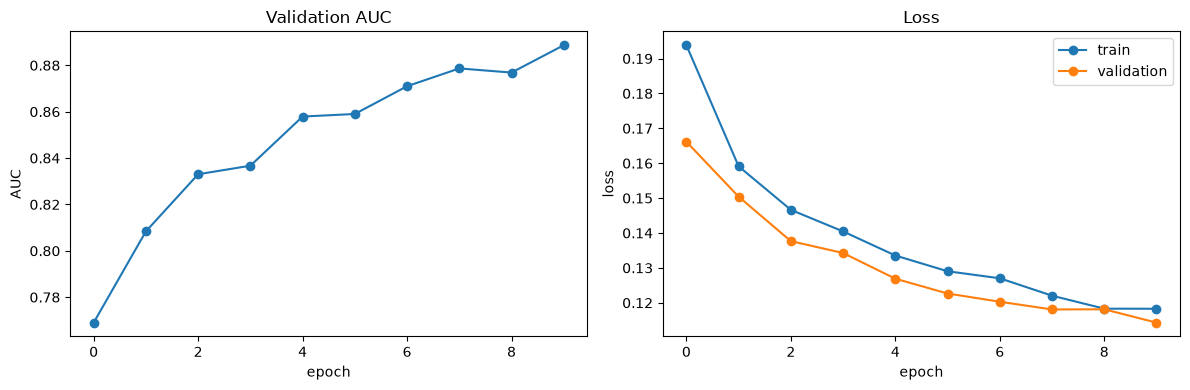

In [15]:
run_name = "resnet_w_normalize"
model = make_model(head=nn.Linear(2048, 512), channels_last=True)
history = train(model, run_name=run_name, epochs=10, margin=0.5, test_dataset=test_normalize, tf=tf_normalize,
                head_lr=1e-3, bf16=True, channels_last=True)
visualize_history(run_name)

Different-person pairs with zero loss: 52%


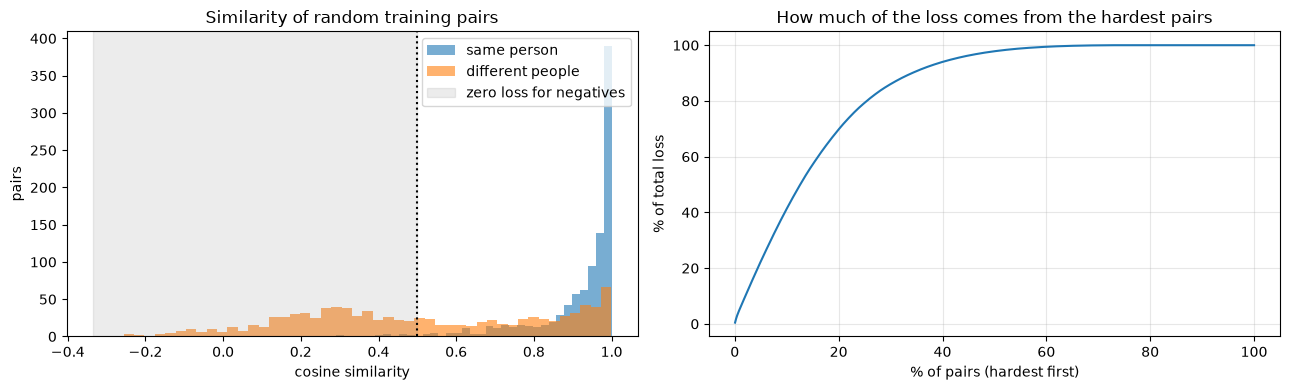

In [16]:
encoder = model
train_eval_dataset = PairDataset(lbl_to_idx_train, 2000, seed=123, tf=tf_normalize)
auc, acc, sims, labels = evaluate(encoder, train_eval_dataset)

margin = 0.5
pos_sims, neg_sims = sims[labels == 1], sims[labels == 0]
pos_loss = 1 - pos_sims
neg_loss = np.maximum(0, neg_sims - margin)

zero_frac = (neg_loss == 0).mean()
print(f"Different-person pairs with zero loss: {zero_frac:.0%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.hist(pos_sims, bins=50, alpha=0.6, label="same person")
ax1.hist(neg_sims, bins=50, alpha=0.6, label="different people")
ax1.axvspan(sims.min(), margin, color="gray", alpha=0.15, label="zero loss for negatives")
ax1.axvline(margin, color="k", linestyle=":")
ax1.set(xlabel="cosine similarity", ylabel="pairs", title="Similarity of random training pairs")
ax1.legend()

all_loss = np.sort(np.concatenate([pos_loss, neg_loss]))[::-1]
share = np.cumsum(all_loss) / all_loss.sum()
ax2.plot(np.arange(1, len(all_loss) + 1) / len(all_loss) * 100, share * 100)
ax2.set(xlabel="% of pairs (hardest first)", ylabel="% of total loss",
        title="How much of the loss comes from the hardest pairs")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

So it is faily confident when people are the same, however there is a different people spike >0.9 sim. So lets visualize some of these, maybe they are the smae people and just poorly labelled

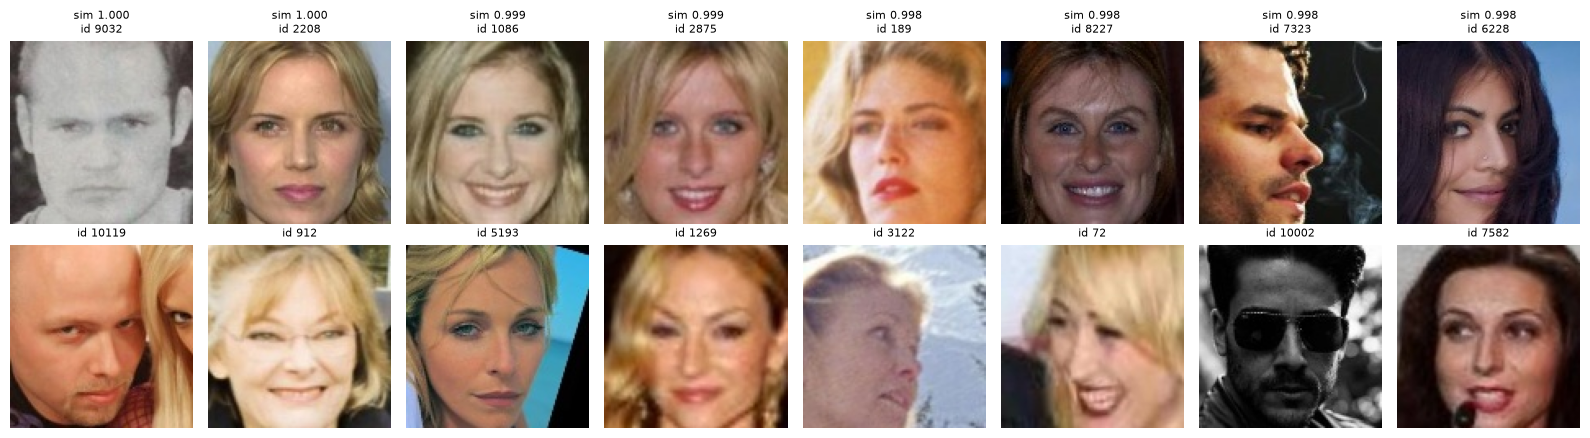

In [17]:
def pair_indices(dataset, k):
    rng = random.Random(dataset.seed * 10_000_000 + k)
    if k % 2 == 0:
        return rng.sample(dataset.by_label[rng.choice(dataset.multi)], 2)
    la, lb = rng.sample(dataset.labels, 2)
    return rng.choice(dataset.by_label[la]), rng.choice(dataset.by_label[lb])


neg_idx = np.where(labels == 0)[0]
top = neg_idx[np.argsort(sims[neg_idx])[::-1][:8]]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for col, k in enumerate(top):
    i, j = pair_indices(train_eval_dataset, int(k))
    for row, img_idx in enumerate([i, j]):
        axes[row, col].imshow(data[img_idx]["image"])
        axes[row, col].set_title(f"id {data[img_idx]['label']}", fontsize=8)
        axes[row, col].set_axis_off()
    axes[0, col].set_title(f"sim {sims[k]:.3f}\nid {data[i]['label']}", fontsize=8)
plt.tight_layout()
plt.show()

So they are clearly different people. But look somewhat similar.

after head:    (3, 512)
before head:   (295, 2048)


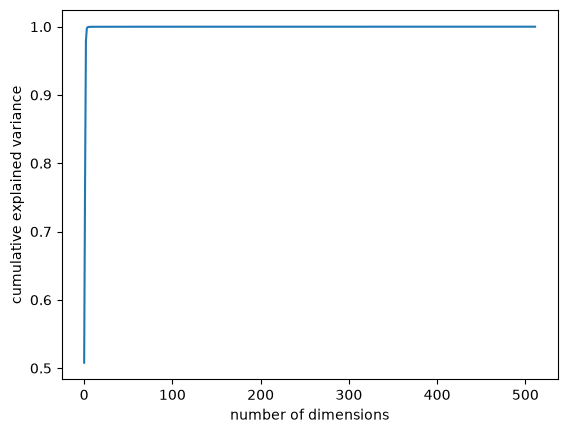

In [18]:
def effective_dims(get_features, dataset, n=1000):
    loader = DataLoader(Subset(dataset, range(0, 2 * n, 2)), batch_size=128)
    feats = []
    with torch.no_grad():
        for a, _, _ in loader:
            feats.append(get_features(a.to(device)).float().cpu())
    Z = torch.cat(feats)
    Z = Z - Z.mean(0)
    s = torch.linalg.svdvals(Z)
    explained = (s**2).cumsum(0) / (s**2).sum()
    return int((explained < 0.9).sum()) + 1, Z.shape[1], explained

encoder.eval()
dims_head, total_head, explained_head = effective_dims(lambda x: encoder(x), train_eval_dataset)
dims_backbone, total_backbone, _ = effective_dims(lambda x: encoder.backbone(x).pooler_output.flatten(1), train_eval_dataset)
print("after head:   ", (dims_head, total_head))
print("before head:  ", (dims_backbone, total_backbone))

plt.plot(explained_head.numpy())
plt.xlabel("number of dimensions")
plt.ylabel("cumulative explained variance")
plt.show()

# Lets try a dynamic LR

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


resnet_head_no_resize_20e:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 0:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 0, 'train_loss': 0.19343886386288706, 'val_loss': 0.16811714716628193, 'val_auc': 0.7589589999999999, 'val_acc': 0.7005, 'train_time': 79.69605549797416, 'eval_time': 2.152692660689354}


...

{'epoch': 7, 'train_loss': 0.12172154572499377, 'val_loss': 0.11585513903200627, 'val_auc': 0.8823709999999999, 'val_acc': 0.808, 'train_time': 79.83962116017938, 'eval_time': 2.0995629020035267}


epoch 8:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.11820294625123444, 'val_loss': 0.11541468929871916, 'val_auc': 0.8747310000000001, 'val_acc': 0.8095000000000001, 'train_time': 79.84844144247472, 'eval_time': 2.0740730613470078}


epoch 9:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.11806466615261019, 'val_loss': 0.11168003968894481, 'val_auc': 0.887624, 'val_acc': 0.8160000000000001, 'train_time': 80.0199804212898, 'eval_time': 2.077669210731983}


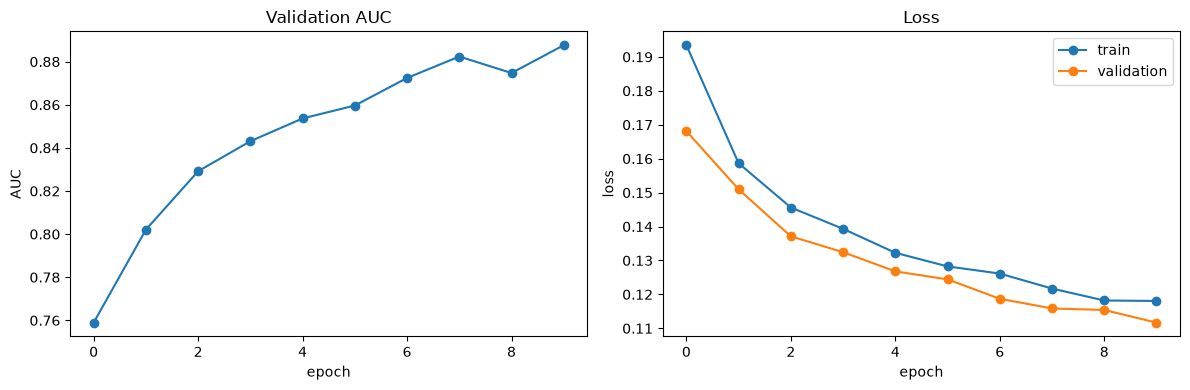

In [10]:
run_name = "resnet_head_no_resize_20e"
model = make_model(head=nn.Linear(2048, 512), channels_last=True)
history = train(model, run_name=run_name, epochs=10, margin=0.5, test_dataset=test_native, tf=tf_native,
                head_lr=1e-3, bf16=True, channels_last=True)
visualize_history(run_name)

resnet_head_no_resize_20e:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 10:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.09638785981499326, 'val_loss': 0.1066444608103484, 'val_auc': 0.8928395, 'val_acc': 0.8305, 'train_time': 79.99297067709267, 'eval_time': 2.0979806799441576}


epoch 11:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 11, 'train_loss': 0.09114083827799543, 'val_loss': 0.10842377560958266, 'val_auc': 0.8906525000000001, 'val_acc': 0.8215, 'train_time': 80.19283820874989, 'eval_time': 2.083516700193286}


...

{'epoch': 17, 'train_loss': 0.10847323047249671, 'val_loss': 0.1062211877759546, 'val_auc': 0.894657, 'val_acc': 0.825, 'train_time': 80.102324295789, 'eval_time': 2.0802072919905186}


epoch 18:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 18, 'train_loss': 0.10738147408856302, 'val_loss': 0.10584407284483313, 'val_auc': 0.8947640000000001, 'val_acc': 0.8300000000000001, 'train_time': 79.98923838883638, 'eval_time': 2.046984428539872}


epoch 19:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 19, 'train_loss': 0.10894370796944937, 'val_loss': 0.10533733701333403, 'val_auc': 0.894877, 'val_acc': 0.8295, 'train_time': 79.9763601962477, 'eval_time': 2.069820823147893}


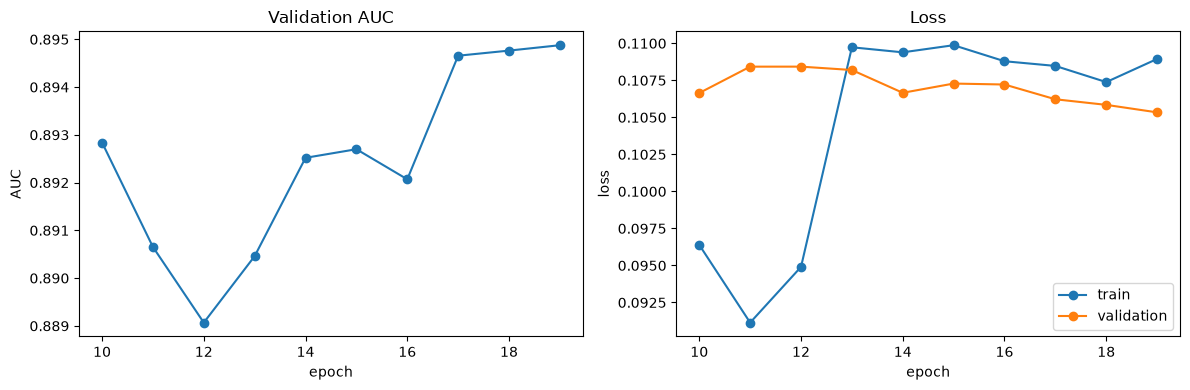

In [13]:
history = train(model, run_name=run_name, epochs=10, margin=0.5, test_dataset=test_native, tf=tf_native,
                lr=1e-5, head_lr=1e-4, bf16=True, channels_last=True, epoch_offset=10)
visualize_history(run_name)

Barely did anything...

resnet_head_no_resize_20e:   0%|          | 0/10 [00:00<?, ?it/s]

epoch 20:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 20, 'train_loss': 0.10796631255742077, 'val_loss': 0.10877257127687336, 'val_auc': 0.890703, 'val_acc': 0.8225, 'train_time': 79.26615152694285, 'eval_time': 2.0680216252803802}


epoch 21:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 21, 'train_loss': 0.1079859965197418, 'val_loss': 0.10768491069972515, 'val_auc': 0.893375, 'val_acc': 0.8255, 'train_time': 79.62989063374698, 'eval_time': 2.0838782358914614}


...

{'epoch': 27, 'train_loss': 0.10349750575964409, 'val_loss': 0.10662614909559488, 'val_auc': 0.892882, 'val_acc': 0.8265, 'train_time': 79.72791018895805, 'eval_time': 2.072527362033725}


epoch 28:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 28, 'train_loss': 0.10161758089900169, 'val_loss': 0.10484336085990072, 'val_auc': 0.893837, 'val_acc': 0.831, 'train_time': 79.99193402193487, 'eval_time': 2.081441195681691}


epoch 29:   0%|          | 0/782 [00:00<?, ?it/s]

{'epoch': 29, 'train_loss': 0.10230159188818444, 'val_loss': 0.1042374228942208, 'val_auc': 0.8970785, 'val_acc': 0.8380000000000001, 'train_time': 79.80316929891706, 'eval_time': 2.1012490149587393}


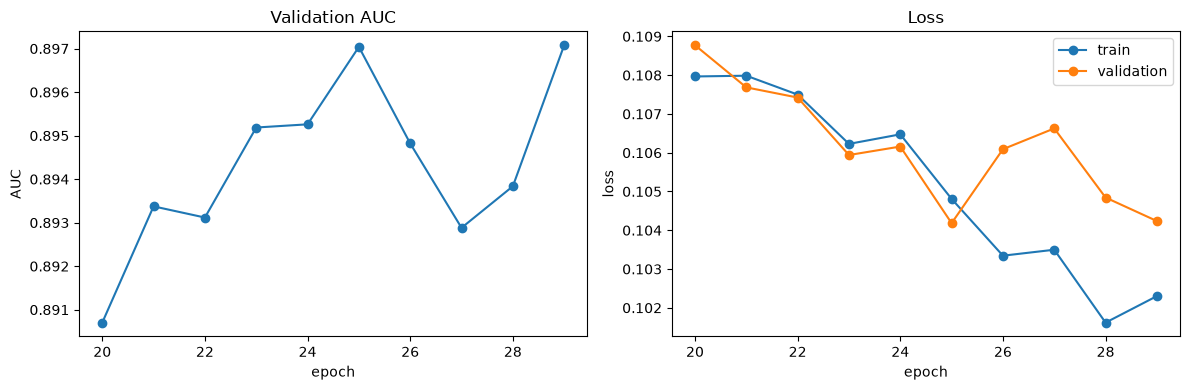

In [14]:
history = train(model, run_name=run_name, epochs=10, margin=0.5, test_dataset=test_native, tf=tf_native,
                lr=5e-5, head_lr=5e-4, bf16=True, channels_last=True, epoch_offset=20)
visualize_history(run_name)